In [14]:
!pip install -q imagehash

In [29]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import imagehash
from PIL import Image
from tqdm.auto import tqdm
from joblib import Parallel, delayed

# Parámetros del proyecto
SEMILLA = 42
TAM = 384
UMBRAL_DUPLICADO = 0.01

# Rutas
ROOT = Path("/kaggle/input/competitions/aptos2019-blindness-detection")
TRABAJO = Path("/kaggle/working")
PAQUETE = TRABAJO / "aptos_384"
IMAGENES = PAQUETE / "imagenes"
REPORTES = PAQUETE / "reportes"

for carpeta in (IMAGENES, REPORTES):
    carpeta.mkdir(parents=True, exist_ok=True)

NOMBRES = {0: "Sin RD", 1: "Leve", 2: "Moderada", 3: "Severa", 4: "Proliferativa"}
ORDEN = list(NOMBRES.values())

In [16]:
df = pd.read_csv(ROOT / "train.csv")
df["path"] = df["id_code"].map(lambda x: ROOT / "train_images" / f"{x}.png")
df["clase"] = df["diagnosis"].map(NOMBRES)

faltantes = (~df["path"].map(Path.exists)).sum()
print("Imágenes:", len(df), "| Faltantes:", faltantes)
assert faltantes == 0, "Hay imágenes faltantes, revisa la ruta ROOT"

Imágenes: 3662 | Faltantes: 0


                  n     %
clase                    
Sin RD         1805  49.3
Leve            370  10.1
Moderada        999  27.3
Severa          193   5.3
Proliferativa   295   8.1

Exactitud de referencia (siempre 'Sin RD'): 49.3%
Razón de desbalance (clase mayor / menor): 9.4


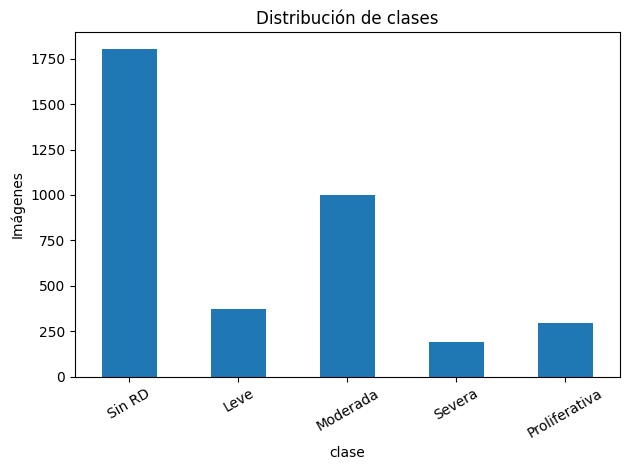

In [17]:
conteo = df["clase"].value_counts().reindex(ORDEN)
dist = pd.DataFrame({"n": conteo, "%": (conteo / len(df) * 100).round(1)})
dist.to_csv(REPORTES / "distribucion_original.csv")

print(dist)
print(f"\nExactitud de referencia (siempre 'Sin RD'): {conteo.max() / len(df):.1%}")
print(f"Razón de desbalance (clase mayor / menor): {conteo.max() / conteo.min():.1f}")

conteo.plot.bar(rot=30, ylabel="Imágenes", title="Distribución de clases")
plt.tight_layout()
plt.savefig(REPORTES / "distribucion_clases.png", dpi=150)
plt.show()

In [18]:
df["ancho"], df["alto"] = zip(*[Image.open(p).size for p in tqdm(df["path"])])
df["tamano"] = df["ancho"].astype(str) + "x" + df["alto"].astype(str)

print(df["tamano"].value_counts().head(10))

top = df["tamano"].value_counts().head(6).index
res_clase = pd.crosstab(
    df.loc[df["tamano"].isin(top), "tamano"],
    df["clase"],
    normalize="index"
).reindex(columns=ORDEN, fill_value=0).round(2)

res_clase.to_csv(REPORTES / "resolucion_vs_clase.csv")
res_clase

  0%|          | 0/3662 [00:00<?, ?it/s]

tamano
1050x1050    974
2416x1736    638
2588x1958    533
3216x2136    410
2048x1536    351
819x614      287
3388x2588    141
1504x1000     92
1844x1226     61
4288x2848     52
Name: count, dtype: int64


clase,Sin RD,Leve,Moderada,Severa,Proliferativa
tamano,,,,,
1050x1050,0.93,0.02,0.04,0.00,0.01
2048x1536,1.00,0.00,0.00,0.00,0.00
2416x1736,0.05,0.37,0.37,0.09,0.13
2588x1958,0.43,0.08,0.31,0.09,0.09
3216x2136,0.00,0.03,0.75,0.08,0.14
819x614,0.97,0.02,0.00,0.00,0.00


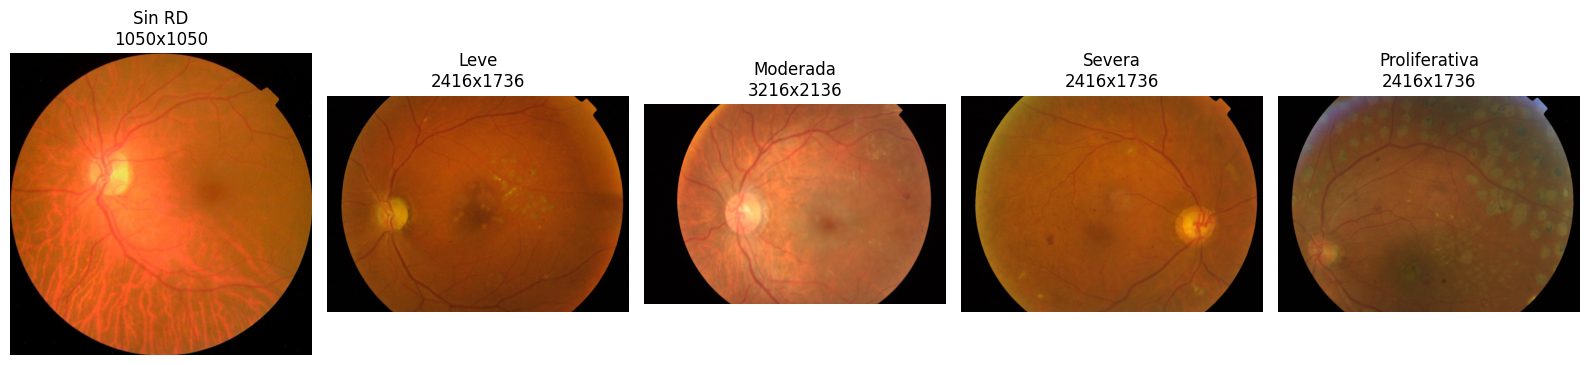

In [19]:
fig, axes = plt.subplots(1, 5, figsize=(16, 4))

for clase, ax in enumerate(axes):
    fila = df[df["diagnosis"] == clase].sample(1, random_state=SEMILLA).iloc[0]
    ax.imshow(Image.open(fila["path"]))
    ax.set_title(f"{NOMBRES[clase]}\n{fila['tamano']}")
    ax.axis("off")

plt.tight_layout()
plt.savefig(REPORTES / "ejemplos_por_clase.png", dpi=150)
plt.show()

In [20]:
CACHE_HASH = TRABAJO / "hashes.csv"

def calcular_phash(ruta):
    return str(imagehash.phash(Image.open(ruta)))

if CACHE_HASH.exists():
    hashes = pd.read_csv(CACHE_HASH)
    print("Hashes cargados desde la caché")
else:
    valores = Parallel(n_jobs=-1)(
        delayed(calcular_phash)(p) for p in tqdm(df["path"])
    )
    hashes = pd.DataFrame({"id_code": df["id_code"], "phash": valores})
    hashes.to_csv(CACHE_HASH, index=False)

df = df.drop(columns=["phash", "grupo"], errors="ignore").merge(hashes, on="id_code")
df["grupo"] = df.groupby("phash").ngroup()

Hashes cargados desde la caché


In [21]:
resumen = df.groupby("grupo")["diagnosis"].agg(["size", "nunique"])
conflictos = resumen[(resumen["size"] > 1) & (resumen["nunique"] > 1)].index

print("Grupos duplicados:", (resumen["size"] > 1).sum())
print("Imágenes en duplicados:", df["grupo"].map(resumen["size"]).gt(1).sum())
print("Grupos con etiquetas distintas:", len(conflictos))

def miniatura(ruta):
    img = Image.open(ruta).convert("L").resize((128, 128))
    return np.asarray(img, dtype=np.float32) / 255

filas = []
for g in conflictos:
    rutas = df.loc[df["grupo"] == g, "path"].tolist()
    base = miniatura(rutas[0])
    dif = max(np.abs(base - miniatura(r)).mean() for r in rutas[1:])
    filas.append({"grupo": g, "diferencia": dif})

verif = pd.DataFrame(filas).sort_values("diferencia")
verif.to_csv(REPORTES / "verificacion_conflictos.csv", index=False)
print(verif.round(4).to_string(index=False))

Grupos duplicados: 143
Imágenes en duplicados: 295
Grupos con etiquetas distintas: 38
 grupo  diferencia
    19      0.0000
   106      0.0000
   321      0.0000
   417      0.0000
   533      0.0000
   474      0.0000
   548      0.0000
   576      0.0000
  1050      0.0000
   592      0.0000
   600      0.0000
   806      0.0000
  1305      0.0000
   913      0.0000
  1951      0.0000
  1526      0.0000
  2754      0.0000
  2573      0.0000
  2028      0.0000
  2139      0.0000
  2304      0.0000
  2455      0.0000
  2437      0.0000
  2405      0.0000
  2463      0.0000
  3236      0.0000
  3234      0.0000
  3186      0.0000
  3325      0.0000
  2197      0.0000
  2381      0.0000
   643      0.0000
  1668      0.0001
  3091      0.0001
  3266      0.0001
  3436      0.0001
  2252      0.0003
    24      0.0472


In [22]:
grupos_eliminar = verif.loc[verif["diferencia"] < UMBRAL_DUPLICADO, "grupo"]
df_limpio = df[~df["grupo"].isin(grupos_eliminar)].copy().reset_index(drop=True)

comparacion = pd.DataFrame({
    "antes": df["clase"].value_counts(),
    "despues": df_limpio["clase"].value_counts(),
}).reindex(ORDEN)
comparacion["eliminadas"] = comparacion["antes"] - comparacion["despues"]
comparacion["% despues"] = (comparacion["despues"] / len(df_limpio) * 100).round(1)
comparacion.to_csv(REPORTES / "limpieza_por_clase.csv")

print(f"Eliminadas {len(df) - len(df_limpio)} imágenes de {len(grupos_eliminar)} grupos")
print(f"Quedan {len(df_limpio)} imágenes")
comparacion

Eliminadas 79 imágenes de 37 grupos
Quedan 3583 imágenes


,antes,despues,eliminadas,% despues
clase,,,,
Sin RD,1805,1801,4,50.3
Leve,370,360,10,10.0
Moderada,999,975,24,27.2
Severa,193,172,21,4.8
Proliferativa,295,275,20,7.7


In [23]:
def recortar_y_redimensionar(ruta, tam=TAM, umbral=7):
    img = cv2.imread(str(ruta))
    if img is None:
        raise ValueError(f"No se pudo leer {ruta}")

    # 1. Recortar el borde negro
    gris = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    mascara = gris > umbral
    filas = np.where(mascara.any(axis=1))[0]
    cols = np.where(mascara.any(axis=0))[0]
    if len(filas) and len(cols):
        img = img[filas[0]:filas[-1] + 1, cols[0]:cols[-1] + 1]

    # 2. Centrar en un lienzo cuadrado sin deformar
    h, w = img.shape[:2]
    lado = max(h, w)
    lienzo = np.zeros((lado, lado, 3), dtype=img.dtype)
    y0, x0 = (lado - h) // 2, (lado - w) // 2
    lienzo[y0:y0 + h, x0:x0 + w] = img

    # 3. Reducir conservando el detalle
    return cv2.resize(lienzo, (tam, tam), interpolation=cv2.INTER_AREA)

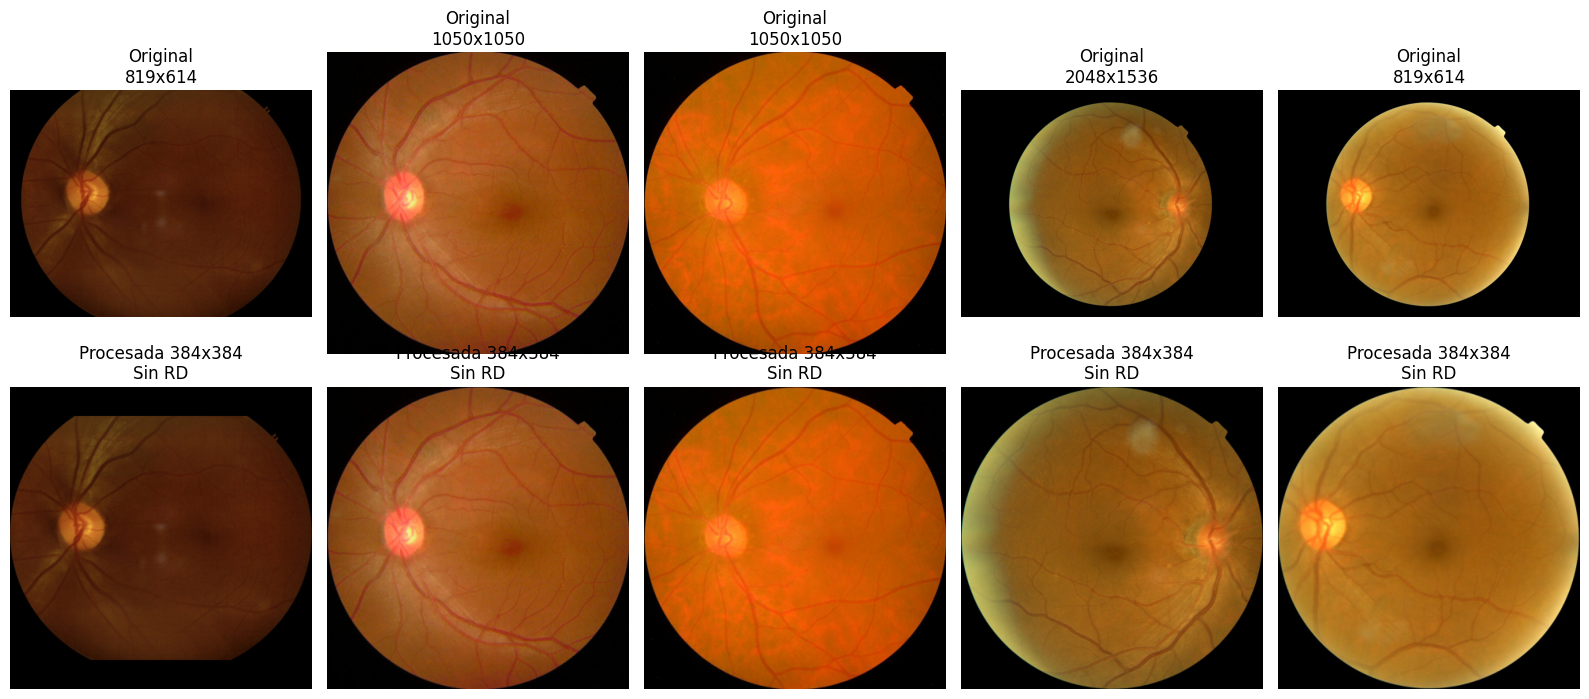

In [24]:
muestra = df_limpio.sample(5, random_state=1)
fig, axes = plt.subplots(2, 5, figsize=(16, 7))

for i, (_, f) in enumerate(muestra.iterrows()):
    axes[0, i].imshow(Image.open(f["path"]))
    axes[0, i].set_title(f"Original\n{f['tamano']}")
    procesada = recortar_y_redimensionar(f["path"])
    axes[1, i].imshow(cv2.cvtColor(procesada, cv2.COLOR_BGR2RGB))
    axes[1, i].set_title(f"Procesada {TAM}x{TAM}\n{f['clase']}")

for ax in axes.flat:
    ax.axis("off")

plt.tight_layout()
plt.savefig(REPORTES / "antes_despues_preprocesamiento.png", dpi=150)
plt.show()

In [25]:
def procesar(id_code, ruta):
    destino = IMAGENES / f"{id_code}.png"
    cv2.imwrite(str(destino), recortar_y_redimensionar(ruta))

pendientes = [
    (f.id_code, f.path)
    for f in df_limpio.itertuples()
    if not (IMAGENES / f"{f.id_code}.png").exists()
]
print("Pendientes:", len(pendientes), "de", len(df_limpio))

Parallel(n_jobs=-1)(delayed(procesar)(i, p) for i, p in tqdm(pendientes))
print("Listo")

Pendientes: 3583 de 3583


  0%|          | 0/3583 [00:00<?, ?it/s]

Listo


In [26]:
archivos = {p.stem for p in IMAGENES.glob("*.png")}
faltan = set(df_limpio["id_code"]) - archivos
print("Procesadas:", len(archivos), "| Faltan:", len(faltan))

danadas = []
for p in tqdm(list(IMAGENES.glob("*.png"))):
    img = cv2.imread(str(p))
    if img is None or img.shape != (TAM, TAM, 3):
        danadas.append(p)

print("Archivos dañados:", len(danadas))
for p in danadas:
    p.unlink()

Procesadas: 3583 | Faltan: 0


  0%|          | 0/3583 [00:00<?, ?it/s]

Archivos dañados: 0


In [31]:
columnas = ["id_code", "diagnosis", "clase", "ancho", "alto", "tamano", "phash", "grupo"]
df_limpio[columnas].to_csv(PAQUETE / "aptos_limpio.csv", index=False)

!cd /kaggle/working && rm -f aptos_384.zip && zip -qr aptos_384.zip aptos_384
!ls -lh /kaggle/working/aptos_384.zip

-rw-r--r-- 1 root root 507M Nov  7 17:39 /kaggle/working/aptos_384.zip


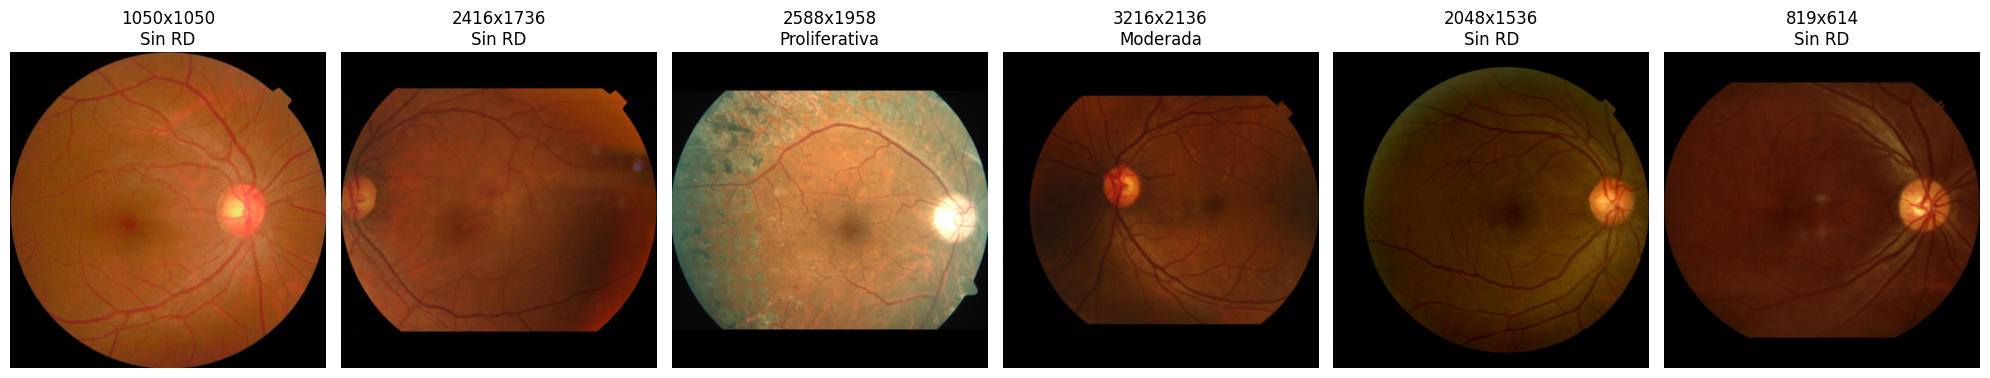

In [30]:
top = df_limpio["tamano"].value_counts().head(6).index
fig, axes = plt.subplots(1, 6, figsize=(20, 4))

for ax, t in zip(axes, top):
    f = df_limpio[df_limpio["tamano"] == t].sample(1, random_state=SEMILLA).iloc[0]
    img = cv2.imread(str(IMAGENES / f"{f['id_code']}.png"))
    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    ax.set_title(f"{t}\n{f['clase']}")
    ax.axis("off")

plt.tight_layout()
plt.savefig(REPORTES / "procesadas_por_resolucion.png", dpi=150)
plt.show()